# Lab 11 - Labeling and Augmenting a Detection Dataset

Object detection begins with reliable labels. In this lab, you will label a small set of images, check the labels, prepare a complete detection dataset, and create safe training augmentations.

## Objectives

- Create pedestrian bounding-box labels in YOLO format.
- Inspect label quality against reference annotations.
- Prepare a fixed train, validation, and test split.
- Augment training images without changing validation or test data.

In [5]:
%pip -q install "albumentations==1.4.24"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import FileLink, display
from PIL import Image

lab_candidates = [
    Path.cwd(),
    Path.cwd() / 'Lab11',
    Path.cwd() / 'Labs' / 'Obj_detection' / 'Lab11',
    Path('/content/Obj_detection/Lab11'),
    Path('/content/Lab11'),
]
for lab_root in lab_candidates:
    if (lab_root / 'labeler.html').exists() and (lab_root / 'detection_dataset.py').exists():
        break
else:
    raise FileNotFoundError('Keep all Lab11 files in the same folder.')

if str(lab_root) not in sys.path:
    sys.path.insert(0, str(lab_root))

import detection_dataset as dd
importlib.reload(dd)

workspace = lab_root / 'work'
workspace.mkdir(exist_ok=True)

## YOLO labels

Each image has a text file with the same base name. Every object occupies one line. This lab has one class, pedestrian, with class ID `0`.

```text
class_id  x_center  y_center  width  height
```

The four box values are normalized by the image width and height, so each lies between 0 and 1.

## 1. Get the images

The Penn-Fudan Pedestrian dataset provides images and instance masks. The masks let us check labels after you create them. The next cell downloads the source once and creates a three-image annotation bundle.

In [7]:
%pip install pip-system-certs

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
source_root = dd.download_pennfudan(workspace / 'source')
practice_archive = dd.make_labeling_practice_bundle(
    source_root, workspace / 'labeling_practice', image_count=3
)

if 'google.colab' in sys.modules:
    from google.colab import files
    files.download(str(practice_archive))
    files.download(str(lab_root / 'labeler.html'))
else:
    print('Annotation images:')
    display(FileLink(practice_archive))
    print('Local labeler:')
    display(FileLink(lab_root / 'labeler.html'))

Extracting the dataset...
Annotation images:


C:\Users\Deerman\OneDrive\Desktop\02_University\Third Year\Computer Vision\my github\Computer-Vision-labs\Lab11\work\labeling_practice\pennfudan_labeling_images.zip

Local labeler:


c:\Users\Deerman\OneDrive\Desktop\02_University\Third Year\Computer Vision\my github\Computer-Vision-labs\Lab11\labeler.html

## 2. Label three images

1. Download the image archive and `labeler.html` from the previous cell.
2. Open `labeler.html` in a browser, load one image, and draw a tight box around each visible pedestrian.
3. Download the matching YOLO label file for every image.
4. Upload or copy the three `.txt` files into `work/manual_labels/`.

Label people separately when they overlap. Include the visible part of a person at an image edge, without extending the box into an unseen region.

In [9]:
manual_labels_dir = workspace / 'manual_labels'
manual_labels_dir.mkdir(exist_ok=True)
print(manual_labels_dir)

c:\Users\Deerman\OneDrive\Desktop\02_University\Third Year\Computer Vision\my github\Computer-Vision-labs\Lab11\work\manual_labels


## 3. Check the labels

The check below compares each uploaded label file with the reference mask for the same image. It reports matched boxes, repeated boxes, extra boxes, and missed pedestrians.

In [10]:
practice_images = sorted((workspace / 'labeling_practice' / 'images').glob('*.png'))
for image_path in practice_images:
    label_path = manual_labels_dir / f'{image_path.stem}.txt'
    if not label_path.exists():
        print(f'{image_path.name}: label file not found')
        continue
    report = dd.annotation_quality_report(source_root, image_path.name, label_path, iou_threshold=0.5)
    print(
        f"{image_path.name}: matched={len(report['matches'])}, "
        f"repeated={len(report['duplicate_indices'])}, "
        f"extra={len(report['extra_indices'])}, missed={len(report['missed_indices'])}"
    )

FudanPed00001.png: label file not found
FudanPed00002.png: label file not found
FudanPed00003.png: label file not found


In [11]:
image_to_review = practice_images[0]
label_to_review = manual_labels_dir / f'{image_to_review.stem}.txt'

if label_to_review.exists():
    manual_class_ids, manual_boxes = dd.read_yolo_labels(label_to_review)
    reference_class_ids, reference_boxes = dd.reference_labels_for_image(source_root, image_to_review.name)
    with Image.open(image_to_review) as image:
        image_array = np.asarray(image.convert('RGB'))

    figure, axes = plt.subplots(1, 2, figsize=(14, 6))
    dd.plot_yolo_sample(axes[0], image_array, manual_class_ids, manual_boxes)
    axes[0].set_title('Manual labels')
    dd.plot_yolo_sample(axes[1], image_array, reference_class_ids, reference_boxes)
    axes[1].set_title('Reference labels')
    plt.show()
else:
    print(f'Save {label_to_review.name} in {manual_labels_dir} and run this cell again.')

Save FudanPed00001.txt in c:\Users\Deerman\OneDrive\Desktop\02_University\Third Year\Computer Vision\my github\Computer-Vision-labs\Lab11\work\manual_labels and run this cell again.


## 4. Prepare the complete dataset

Your labels provide annotation and quality-check practice. The complete dataset uses verified mask-derived annotations so training starts from a reliable full set. It is split at image level before any augmentation, with a fixed seed so the next lab uses the same train, validation, and test images.

In [12]:
base_dataset_root = dd.prepare_base_dataset(
    source_root, workspace / 'pennfudan_yolo', seed=2026
)
base_summary = dd.validate_yolo_dataset(base_dataset_root)
print('Base dataset:', base_dataset_root)
for split, counts in base_summary.items():
    print(f"{split}: {counts['images']} images, {counts['boxes']} boxes")
print('Configuration:', base_dataset_root / 'data.yaml')

Base dataset: C:\Users\Deerman\OneDrive\Desktop\02_University\Third Year\Computer Vision\my github\Computer-Vision-labs\Lab11\work\pennfudan_yolo
train: 119 images, 291 boxes
val: 26 images, 68 boxes
test: 25 images, 64 boxes
Configuration: C:\Users\Deerman\OneDrive\Desktop\02_University\Third Year\Computer Vision\my github\Computer-Vision-labs\Lab11\work\pennfudan_yolo\data.yaml


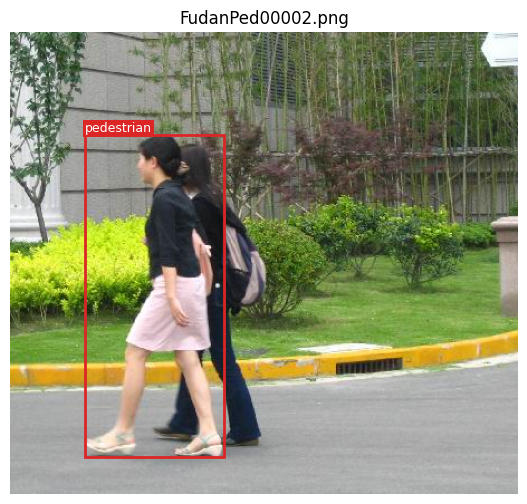

In [13]:
image_array, class_ids, boxes, image_path = dd.load_yolo_sample(base_dataset_root, 'train', index=0)
figure, axes = plt.subplots(figsize=(7, 6))
dd.plot_yolo_sample(axes, image_array, class_ids, boxes)
axes.set_title(image_path.name)
plt.show()

## 5. Augment training images

The augmentation creates one separate copy of every training image. It uses a horizontal flip and mild brightness or contrast variation. Validation and test images are copied unchanged.

In [14]:
augmented_dataset_root = dd.make_augmented_dataset(
    base_dataset_root,
    workspace / 'pennfudan_yolo_augmented',
    copies_per_image=1,
    seed=2026,
)
augmented_summary = dd.validate_yolo_dataset(augmented_dataset_root)
for split, counts in augmented_summary.items():
    print(f"{split}: {counts['images']} images, {counts['boxes']} boxes")

assert augmented_summary['val'] == base_summary['val']
assert augmented_summary['test'] == base_summary['test']
print('Validation and test splits are unchanged.')

train: 238 images, 582 boxes
val: 26 images, 68 boxes
test: 25 images, 64 boxes
Validation and test splits are unchanged.


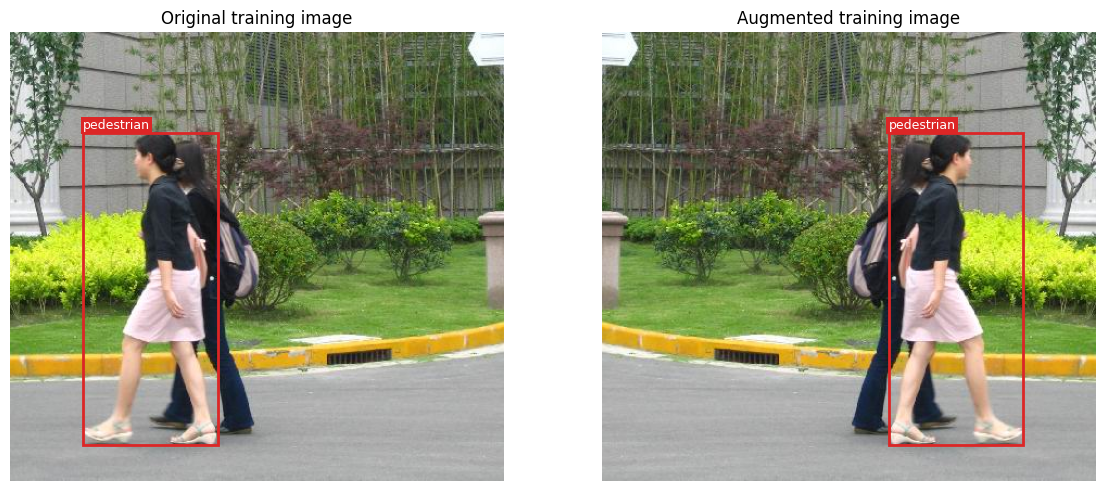

In [15]:
original_image, original_classes, original_boxes, original_path = dd.load_yolo_sample(
    base_dataset_root, 'train', index=0
)
augmented_path = augmented_dataset_root / 'train' / 'images' / f'{original_path.stem}_aug1.png'
augmented_classes, augmented_boxes = dd.read_yolo_labels(
    augmented_dataset_root / 'train' / 'labels' / f'{original_path.stem}_aug1.txt'
)
with Image.open(augmented_path) as image:
    augmented_image = np.asarray(image.convert('RGB'))

figure, axes = plt.subplots(1, 2, figsize=(14, 6))
dd.plot_yolo_sample(axes[0], original_image, original_classes, original_boxes)
axes[0].set_title('Original training image')
dd.plot_yolo_sample(axes[1], augmented_image, augmented_classes, augmented_boxes)
axes[1].set_title('Augmented training image')
plt.show()

## Check your understanding

1. Why are training images augmented after the split, rather than before it?
2. Why does a horizontal flip require an updated bounding box?
3. Why would a vertical flip be a poor default choice for pedestrian images?
4. What label problem could lead to a pedestrian being missed during training?

1) To prevent data leakage. Augmenting first puts modified copies of the exact same image into both your training and validation sets, letting the model cheat.

2) The object changes location. Mirroring the image moves the pedestrian to the opposite side, so the box coordinates must be updated to match.

3) It creates impossible data. Pedestrians do not walk upside down in the real world.

4) Missing bounding boxes. If a pedestrian in the image isn't labeled, the model gets penalized for finding them, which accidentally teaches it to ignore people.